In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

pd.set_option('display.float_format', '{:.3f}'.format)

Задание 1

В файле первый столбец без названия, это сохраненный индекс строк. Тогда столбцов получается 38, как в примере.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

In [3]:
events.shape

(29710, 38)

In [4]:
events.iloc[:10,[2,3,4,9,12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Названия некоторых столбцов длинные, поэтому сразу отправим их в переменные.

In [5]:
X = 'X Coordinate on the Ice Rink'
Y = 'Y Coordinate on the Ice Rink'
side = "Home Team's Defending Side"

away_cols = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Away Team's Goalie"]
home_cols = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Home Team's Goalie"]
away_goalie = "Away Team's Goalie"
home_goalie = "Home Team's Goalie"

Задание 2

Счет в данных накопленный, то есть итоговый счет матча это максимум по всем его событиям. Сколько было овертаймов, видно по номеру последнего периода: 3 значит игра закончилась в основное время, 4 значит был один овертайм, 5 значит два и так далее.

In [6]:
games = events.groupby('Game ID').agg({'Date': 'first',
                                       'Away Team': 'first',
                                       'Home Team': 'first',
                                       'Cumulated Away Score': 'max',
                                       'Cumulated Home Score': 'max',
                                       'Period': 'max'})
games.columns = ['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Period']

In [7]:
def outcome(p):
    if p <= 3:
        return 'Final'
    if p == 4:
        return 'Final/OT'
    return f'Final/{p - 3}OT'

In [8]:
games['Outcome'] = games['Period'].apply(outcome)
games = games.drop(columns='Period')

In [9]:
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [10]:
games.iloc[-5:,-4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


Задание 3

Как в примере, сначала идут хозяева, потом гости.

In [11]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")

In [12]:
gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [13]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

Задание 4

In [14]:
games['Total Score'] = games['Away Score'] + games['Home Score']

In [15]:
games['Total Score'].describe()

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64

Всего в плей-офф 82 матча. В среднем за игру забивали почти 6 шайб (5.93), медиана тоже 6. Половина матчей укладывается в промежуток от 5 до 7 голов, стандартное отклонение около 2.3 гола. Минимум 1 гол за матч, максимум 15.

Задание 5

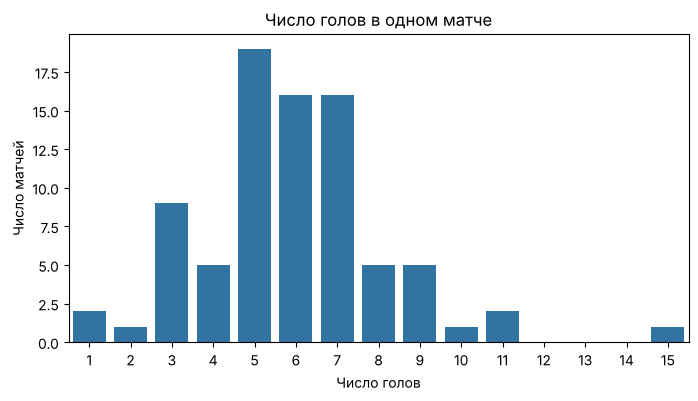

In [16]:
plt.figure(figsize=(8, 4))
sns.countplot(x=games['Total Score'],
              order=range(games['Total Score'].min(), games['Total Score'].max() + 1))
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.title('Число голов в одном матче')
plt.show()

Чаще всего за матч забивали 5 голов (19 матчей), потом 6 и 7 (по 16 матчей). Распределение скошено вправо: слева значения быстро упираются в единицу, а справа есть матчи на 8-11 голов и один матч на 15, между 11 и 15 нет. Совсем мало голов бывает редко, с одним или двумя голами всего 3 матча. Немного странно, что матчей с 3 голами (9) больше, чем с 4 (5), но на 82 матчах это вполне может быть случайностью.

Задание 6

In [17]:
[gameInfo(i) for i in games.index[games['Total Score'] == games['Total Score'].min()]]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [18]:
[gameInfo(i) for i in games.index[games['Total Score'] == games['Total Score'].max()]]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Самых нерезультативных матчей два, оба закончились 1:0 в овертайме. То есть в основное время там вообще никто не забил. Самый результативный матч один: Colorado дома обыграл Minnesota 9:6.

Задание 7

Для каждой игры берем все имена из столбцов с игроками на льду (вместе с вратарями) и считаем уникальные. Все 14 столбцов ставим в один через `melt`. Пустые значения (NaN) не учитываем.

In [19]:
games['Player Count'] = events.melt(id_vars='Game ID', value_vars=away_cols + home_cols).groupby('Game ID')['value'].nunique()
games['Game Info'] = [gameInfo(i) for i in games.index]

In [20]:
games[games['Player Count'] == games['Player Count'].max()][['Game Info', 'Player Count']]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


In [21]:
games['Player Count'].value_counts()

Player Count
38    73
39     8
40     1
Name: count, dtype: int64

У нас максимум 40, а в примере из задания 41. Разница, похоже, в пустых значениях: если не отбрасывать NaN, он считается как еще один "игрок", и получается как раз 41 (проверка ниже). Я считаю правильным ответ 40, потому что NaN это не игрок.

In [22]:
int(events.melt(id_vars='Game ID', value_vars=away_cols + home_cols).groupby('Game ID')['value'].nunique(dropna=False).max())

41

В заявке на матч у команды 20 человек: 18 полевых и 2 вратаря. В 73 матчах из 82 на льду было ровно 38 игроков, то есть все полевые плюс по одному вратарю. В 8 матчах 39, там одна из команд меняла вратаря по ходу игры. И только в одном матче, Montréal - Buffalo (3:8), получилось 40: вратарей меняли обе команды, и на лед вышли вообще все заявленные игроки.

Задание 8

Куда бросает команда, определяем по полю Home Team's Defending Side. Если хозяева защищают левые ворота, то атакуют правые ($X = 89$), а гости атакуют левые ($X = -89$). Если хозяева защищают правые, то наоборот.

Формулу из условия можно записать одной строкой. По $y$ мы смотрим, насколько точка выходит за створ шириной 6 футов, а если не выходит, считаем это расстояние нулем:

$$d(x, y) = \sqrt{(x - X)^2 + \left(\max(|y| - 3,\ 0)\right)^2}$$

При $|y| \leqslant 3$ второе слагаемое равно нулю и остается $|x - X|$, при $|y| > 3$ получаются две другие ветки формулы.

In [23]:
shots = events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])
home = events['Team Making the Play'] == events['Home Team']  
left = events[side] == 'left'
goalX = np.where(home == left, 89, -89)

In [24]:
dy = np.maximum(np.abs(events[Y]) - 3, 0)
events['Shot Length'] = np.sqrt((events[X] - goalX)**2 + dy**2)

In [25]:
events[events['Play Type'].isin(['shot-on-goal','goal','missed-shot'])][['Game ID','Play Type','Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Задание 9

Точных и неточных бросков разное количество, поэтому сравнивать надо не число бросков, а доли.

In [26]:
sh = events[shots].copy()
sh['Shot'] = np.where(sh['Play Type'] == 'missed-shot', 'missed', 'on goal')

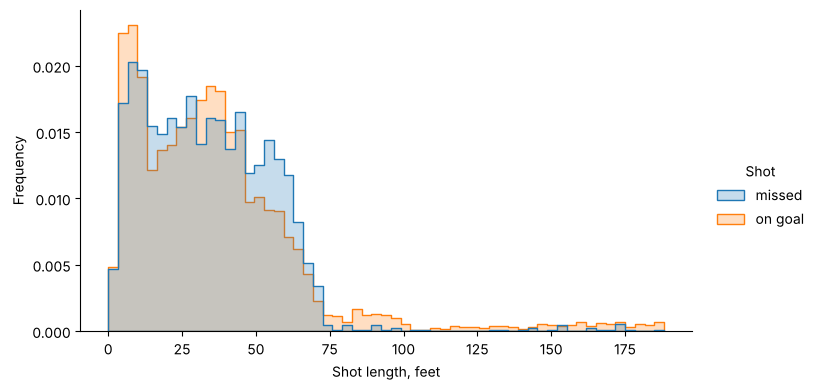

In [27]:
g = sns.displot(data=sh, x='Shot Length', hue='Shot', stat='density',
                common_norm=False, element='step', height=4, aspect=1.8)
g.set_axis_labels('Shot length, feet', 'Frequency')
plt.show()

In [28]:
sh.groupby('Shot')['Shot Length'].median()

Shot
missed    32.249
on goal   31.828
Name: Shot Length, dtype: float64

Распределения в целом похожи. Почти все броски наносятся с расстояния до 70-75 футов, то есть из зоны атаки (синяя линия находится в 64 футах от ворот). У обоих типов самый высокий столбик совсем рядом с воротами, на 5-10 футах: это добивания и броски с пятачка. Медианы почти одинаковые, около 32 футов.

Отличия такие. На 50-65 футах, то есть примерно от синей линии, неточных бросков заметно больше, чем точных: издалека попасть в створ сложнее. А дальше 75 футов наоборот: точные броски встречаются на любом расстоянии вплоть до 190 футов, а неточных там почти нет.

Теперь про длинный хвост точных бросков со своей половины площадки, то есть дальше 89 футов. Посмотрим на голы, забитые с такого расстояния.

In [29]:
far_goals = sh[(sh['Shot Length'] > 89) & (sh['Play Type'] == 'goal')]
far_goals[['Game ID', 'Period', 'Remaining Time', 'Team Making the Play', 'Shot Length']]

,Game ID,Period,Remaining Time,Team Making the Play,Shot Length
587,2025030112,2,03:31,Boston Bruins,89.090
2169,2025030116,3,03:20,Buffalo Sabres,89.051
10308,2025030161,3,03:08,Minnesota Wild,116.103
10669,2025030162,3,00:50,Dallas Stars,162.000
12162,2025030166,3,00:15,Minnesota Wild,167.431
12532,2025030171,3,01:39,Vegas Golden Knights,132.699
14565,2025030176,3,03:36,Vegas Golden Knights,120.266
15320,2025030182,3,01:10,Anaheim Ducks,129.000
15676,2025030183,3,01:33,Anaheim Ducks,172.569
18662,2025030216,3,05:48,Buffalo Sabres,158.152


Таких голов 19, и 18 из них забиты в третьем периоде, почти все в последние 3-4 минуты. Это голы в пустые ворота: проигрывающая команда в конце матча меняет вратаря на шестого полевого игрока, и соперник бросает прямо из своей зоны. Остальные дальние броски в створ, скорее всего, обычные выбросы шайбы из зоны, которые летят в ворота и которые ловит вратарь. Статистика записывает их как бросок в створ. А если такая шайба проходит мимо, это обычно считается не броском, а выбросом или пробросом, поэтому у неточных бросков хвоста почти нет.

Задание 10

Заблокированные броски не берем. Признак «бросок в створ» это True/False, поэтому его среднее по группе и есть доля точных бросков.

In [30]:
ub = events[shots].copy()
ub['Share of Shots on Goal'] = ub['Play Type'] != 'missed-shot'
numshots = ub.groupby(['Game ID', 'Team Making the Play'])[['Share of Shots on Goal']].mean()

In [31]:
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [32]:
numshots['Share of Shots on Goal'].describe()

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64

В среднем команда попадает в створ 64% незаблокированных бросков, у половины значений доля лежит между 58% и 69%. Но в отдельных матчах бывает и 35%, и 86%. Такой разброс понятен: за игру у команды набирается всего около 44 незаблокированных бросков, и несколько удачных или неудачных моментов сильно сдвигают долю. Так что по одному матчу о точности команды судить сложно, лучше смотреть на среднее за весь плей-офф, это следующее задание.

Задание 11

In [33]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()

In [34]:
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64

In [35]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64

Точнее всех Edmonton Oilers, у них в среднем 70.6% бросков в створ. Хуже всех Pittsburgh Penguins, 55.4%, и они заметно отстают даже от следующей за ними команды (Utah, 59.9%). Остальные команды из этих двух списков отличаются друг от друга всего на несколько процентных пунктов.

Интересно, что Carolina Hurricanes в тройке самых неточных команд, хотя по последним матчам из задания 2 видно, что она выиграла у Vegas финал. Значит, точность бросков сама по себе мало говорит о результате.

Задание 12

Бросками в створ считаем shot-on-goal и goal, потому что гол это тоже бросок, который попал в створ. Число сыгранных матчей у каждой команды считаем по таблице games: сколько раз команда встречается среди хозяев и гостей.

In [36]:
ngames = pd.concat([games['Away Team'], games['Home Team']]).value_counts()
sog = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
gl = events[events['Play Type'] == 'goal']

In [37]:
avgshots = pd.DataFrame({'Shot': sog['Team Making the Play'].value_counts() / ngames,
                         'Goal': gl['Team Making the Play'].value_counts() / ngames})
avgshots.index.name = 'Team Making the Play'

In [38]:
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Больше всех в створ бросал Colorado (32.2 за игру), меньше всех Montréal (23.3). По голам лучше всех Minnesota (3.73 за игру), хуже всех Los Angeles и Ottawa, у обеих по 1.25.

Задание 13

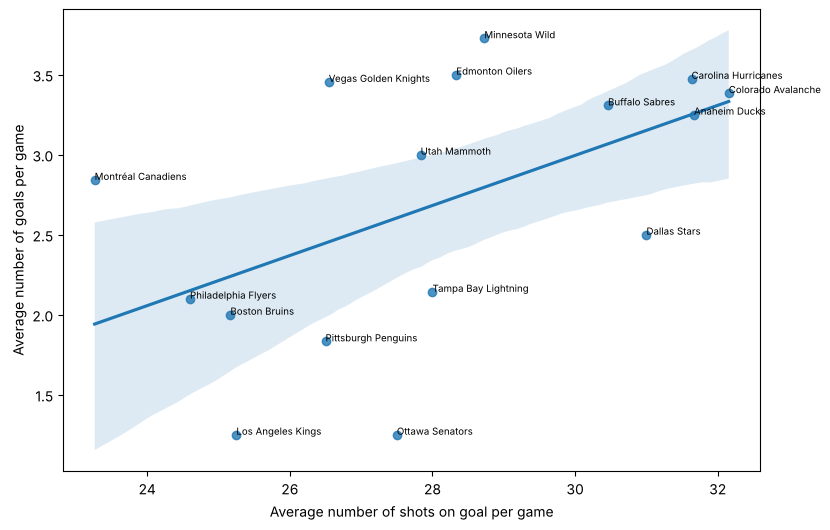

In [39]:
plt.figure(figsize=(9, 6))
sns.regplot(data=avgshots, x='Shot', y='Goal')
for team, r in avgshots.iterrows():
    plt.annotate(team, (r['Shot'], r['Goal']), fontsize=7)
plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.show()

In [40]:
print(avgshots['Shot'].corr(avgshots['Goal']))
print(np.polyfit(avgshots['Shot'], avgshots['Goal'], 1))

0.5207961205304794
[ 0.15644424 -1.69811999]


Связь есть, она положительная: кто больше бросает в створ, тот в среднем больше забивает. Наклон линии 0.16, то есть примерно 6 лишних бросков за игру дают еще один гол. Но связь не очень сильная, корреляция 0.52. Точки заметно разбросаны вокруг линии, а команд всего 16, поэтому и доверительная полоса широкая.

Сильнее всего от линии отходят Montréal (меньше всех бросков, но 2.8 гола за игру), Vegas и Minnesota (бросают средне, а забивают больше почти всех) и в другую сторону Ottawa, Los Angeles и Dallas. Так что количество бросков важно, но реализация у команд очень разная.

Задание 14

In [41]:
allshots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]

In [42]:
idxmax = allshots['Game ID'].value_counts().idxmax()

In [43]:
gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

Больше всего ударов было в матче Carolina - Ottawa, который закончился во втором овертайме. Это ожидаемо: игра шла больше чем на период дольше обычной, и бросков успело набраться больше, чем в любом другом матче.

Задание 15

По условию в нечетных периодах разворачиваем координаты $(x, y) \mapsto (-x, -y)$, тогда гости во всех периодах бьют в левые ворота, а хозяева в правые.

In [44]:
g15 = allshots[allshots['Game ID'] == idxmax].copy()
odd = g15['Period'] % 2 == 1
g15.loc[odd, [X, Y]] = -g15.loc[odd, [X, Y]]
g15 = g15.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

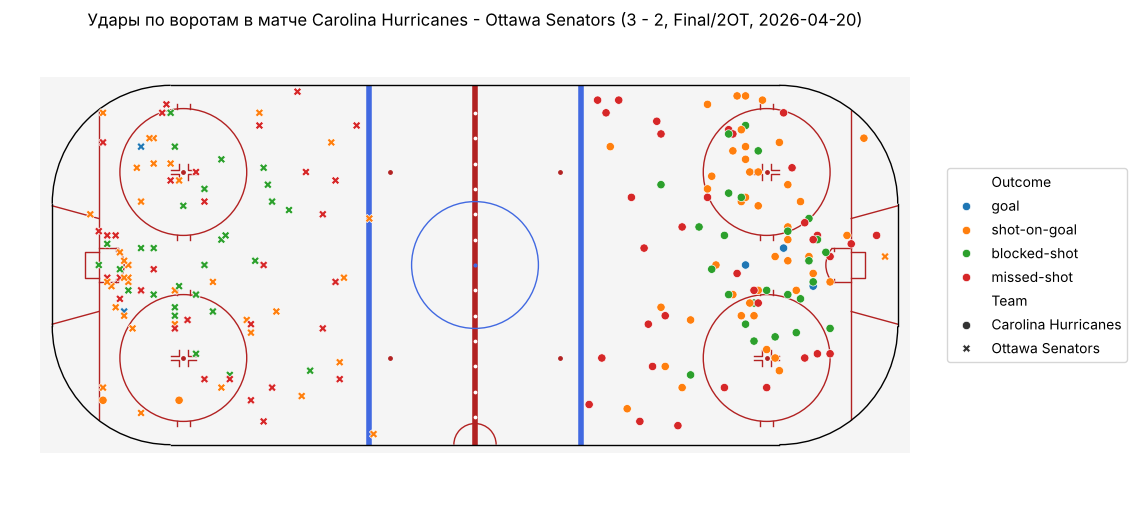

In [45]:
plt.figure(figsize=(12, 6))
plot_rink()
sns.scatterplot(data=g15, x=X, y=Y, hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'])
plt.axis('equal')
plt.axis('off')
plt.title(f'Удары по воротам в матче {gameInfo(idxmax)}')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [46]:
g15.groupby(['Team', 'Outcome']).size().unstack()

Outcome,blocked-shot,goal,missed-shot,shot-on-goal
Team,,,,
Carolina Hurricanes,26,3,34,46
Ottawa Senators,28,2,32,37


In [47]:
g15.groupby('Outcome')['Shot Length'].describe()[['count', 'min', '50%', 'max']]

,count,min,50%,max
Outcome,,,,
blocked-shot,54.000,0.000,27.386,54.626
goal,5.000,9.220,16.031,26.926
missed-shot,66.000,2.000,38.063,69.971
shot-on-goal,83.000,2.236,27.803,186.000


Carolina (кружки) бьет вправо, Ottawa (крестики) влево. Почти все удары нанесены из зоны атаки, из-за синей линии бросали всего несколько раз. Больше всего бросков у самых ворот и в районе кругов вбрасывания. Все 5 голов забиты с близкого расстояния, от 9 до 27 футов. У бросков в створ и заблокированных бросков медиана около 27 футов, а неточные бросали дальше всего, медиана 38 футов. По таблице Carolina нанесла больше ударов (109 против 99) и чаще попадала в створ (49 против 39 вместе с голами).

Задание 16

Если на 10-м месте несколько игроков с одинаковым результатом, `nlargest(10, keep='all')` показывает всех.

In [48]:
goals = events[events['Play Type'] == 'goal']

In [49]:
scorers = goals['Player in the Event #1'].value_counts()
scorers.nlargest(10, keep='all')

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Matt Boldy           7
Mark Stone           7
Name: count, dtype: int64

В списке 12 игроков, а не 10: шестеро забили по 7 голов и делят места с 7-го по 12-е. Это суммарные голы за весь плей-офф, поэтому у игроков команд, которые сыграли больше матчей, заранее есть преимущество. Так и вышло: 10 из 12 играют за Vegas (22 матча), Carolina (19) и Montréal (19), исключения только Matt Boldy из Minnesota и Nathan MacKinnon из Colorado. Больше всех забил Brett Howden из Vegas, 14 голов.

Задание 17

Первая и вторая передачи лежат в разных столбцах. Ставим их друг под друга и считаем, сколько раз встречается каждый игрок.

In [50]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).value_counts()
assists.nlargest(10, keep='all')

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

По передачам впереди два игрока Vegas: Jack Eichel (20) и Mitch Marner (19), у остальных намного меньше. Команд здесь уже больше, в десятке есть Colorado и два игрока Minnesota, хотя Minnesota сыграла всего 11 матчей.

Задание 18

Складываем голы и передачи.

In [51]:
points = scorers.add(assists, fill_value=0).astype(int)
points.nlargest(10, keep='all')

Player in the Event #1
Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Lane Hutson        16
Logan Stankoven    16
Nick Suzuki        16
Pavel Dorofeyev    16
Name: count, dtype: int64

Лучший по очкам Mitch Marner: 10 голов и 19 передач, всего 29. У него большой отрыв, второй Jack Eichel набрал 22. В списке 11 человек, потому что четверо набрали по 16 очков, и все они из трех команд, которые сыграли больше всех матчей: Vegas, Carolina и Montréal.

Задание 19

Сыгранным считаем матч, в котором игрок хотя бы раз был на льду. Оставляем только тех, кто сыграл не меньше 4 матчей (это минимальная длина серии). Иначе наверх вылезают игроки с одной игрой: например, в силовых приемах (задание 20) первыми оказались бы Alexander Petrovic и Alex Turcotte, у которых по 6 приемов в единственном матче.

In [52]:
gp = events.melt(id_vars='Game ID', value_vars=away_cols + home_cols).groupby('value')['Game ID'].nunique()
gp = gp[gp >= 4]

In [53]:
shots_p = sog['Player in the Event #1'].value_counts()
(shots_p / gp).nlargest(10, keep='all')

Player in the Event #1
Jason Robertson    5.000
Dylan Guenther     4.500
Nikita Kucherov    4.429
Matt Boldy         4.364
Quinton Byfield    4.250
Darren Raddysh     4.000
Joel Eriksson Ek   4.000
Alex Laferriere    3.750
David Pastrnak     3.667
Nathan MacKinnon   3.615
dtype: float64

Здесь среднее за игру, и длинный плей-офф уже не помогает. Скорее наоборот: 7 из 10 игроков из команд, которые вылетели после 4-7 матчей (Dallas, Utah, Tampa Bay, Los Angeles, Boston), а из Vegas, Carolina и Montréal в десятке нет никого. Больше всех бросал Jason Robertson из Dallas, 5 бросков в створ за игру.

Задание 20

Число матчей берем то же, что в задании 19.

In [54]:
hits = events[events['Play Type'] == 'hit']
hits_p = hits['Player in the Event #1'].value_counts()
(hits_p / gp).nlargest(10, keep='all')

Player in the Event #1
Lawson Crouse      6.333
Yakov Trenin       5.667
Dylan Cozens       5.500
Vasily Podkolzin   5.333
Ivan Barbashev     5.000
Marcus Foligno     5.000
Owen Tippett       4.833
William Carrier    4.789
Colton Dach        4.600
Cole Smith         4.545
dtype: float64

Больше всех силовых приемов у Lawson Crouse из Utah, больше 6 за игру. В десятке игроки семи разных команд, и явной связи с тем, как далеко прошла команда, тут не видно.

Задание 21

Для каждого гола находим вратаря, который его пропустил: если забили хозяева, это вратарь гостей на льду в момент гола, и наоборот.

Тут есть подвох в данных: у голов в овертаймах не записано, кто был на льду, поле вратаря пустое (таблица ниже). Если это не учесть, вратарь, пропустивший гол в овертайме, попадет в список как отыгравший на ноль. Так получается, например, с Jakub Dobes в матче Montréal - Tampa Bay (0:1 ОТ). Поэтому пустые поля вратарей заполняем значением из предыдущего события того же матча (`ffill`).

In [55]:
goals.loc[goals['Period'] > 3, ['Game ID', 'Period', away_goalie, home_goalie]].head()

,Game ID,Period,Away Team's Goalie,Home Team's Goalie
1853,2025030115,4,NaN,NaN
2548,2025030121,4,NaN,NaN
2977,2025030122,4,NaN,NaN
3296,2025030123,4,NaN,NaN
4351,2025030126,4,NaN,NaN


In [56]:
gk = events.groupby('Game ID')[[away_goalie, home_goalie]].ffill()

In [57]:
played_g = events.melt(id_vars='Game ID', value_vars=[away_goalie, home_goalie], value_name='Goalie')
played_g = played_g[['Game ID', 'Goalie']].dropna().drop_duplicates()

In [58]:
home_goal = goals['Team Making the Play'] == goals['Home Team']
conceded_by = np.where(home_goal, gk.loc[goals.index, away_goalie], gk.loc[goals.index, home_goalie])
conceded = pd.DataFrame({'Game ID': goals['Game ID'], 'Goalie': conceded_by}).dropna().drop_duplicates()

In [59]:
m = played_g.merge(conceded, how='left', indicator=True)
shutouts = m[m['_merge'] == 'left_only']
sorted(shutouts['Goalie'].unique())

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

In [60]:
pd.set_option('display.max_colwidth', None)
shutouts.assign(Game=shutouts['Game ID'].map(gameInfo))[['Goalie', 'Game']].sort_values('Goalie')

,Goalie,Game
11,Andrei Vasilevskiy,"Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)"
85,Brandon Bussi,"Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)"
18,Dan Vladar,"Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)"
110,Dan Vladar,"Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)"
73,Frederik Andersen,"Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)"
101,Frederik Andersen,"Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)"
142,Frederik Andersen,"Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)"
91,Joonas Korpisalo,"Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)"
151,Scott Wedgewood,"Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)"


Получилось шесть вратарей. Четверо отыграли на ноль весь матч: Frederik Andersen из Carolina даже три раза, Dan Vladar из Philadelphia два раза, а также Andrei Vasilevskiy (Tampa Bay) и Brandon Bussi (Carolina). Еще двое вышли на замену и до конца игры ничего не пропустили: Joonas Korpisalo сменил Swayman в матче, где Boston проиграл Buffalo 1:6, а Scott Wedgewood сменил Blackwood в матче Colorado - Minnesota (4:3 ОТ).

Задание 22

Вопрос: что сильнее связано с тем, как далеко команда прошла в плей-офф: сколько она бросает или сколько забивает?

Как меру успеха возьмем число сыгранных матчей. Кто прошел дальше, тот сыграл больше. Мера грубая, потому что число матчей зависит и от длины серий, но для 16 команд разница между вылетом в первом раунде (4-7 игр) и финалом (около 20 игр) все равно видна хорошо.

In [61]:
progress = avgshots.copy()
progress['Games'] = ngames
progress.sort_values('Games', ascending=False)

,Shot,Goal,Games
Team Making the Play,,,
Vegas Golden Knights,26.545,3.455,22
Carolina Hurricanes,31.632,3.474,19
Montréal Canadiens,23.263,2.842,19
Buffalo Sabres,30.462,3.308,13
Colorado Avalanche,32.154,3.385,13
Anaheim Ducks,31.667,3.250,12
Minnesota Wild,28.727,3.727,11
Philadelphia Flyers,24.600,2.100,10
Tampa Bay Lightning,28.000,2.143,7


In [62]:
progress.corr()['Games']

Shot    0.104
Goal    0.636
Games   1.000
Name: Games, dtype: float64

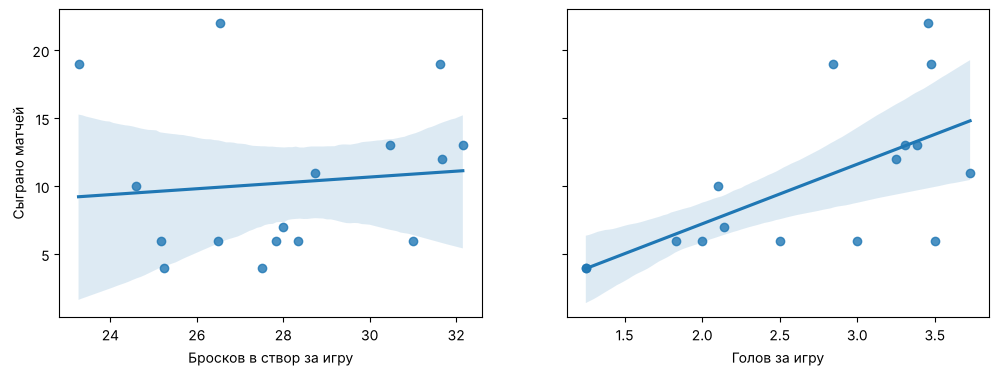

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.regplot(data=progress, x='Shot', y='Games', ax=ax[0])
sns.regplot(data=progress, x='Goal', y='Games', ax=ax[1])
ax[0].set_xlabel('Бросков в створ за игру')
ax[1].set_xlabel('Голов за игру')
ax[0].set_ylabel('Сыграно матчей')
ax[1].set_ylabel('')
plt.show()

С бросками связи почти нет (корреляция 0.10), а с голами она заметная (0.64). Это видно и по отдельным командам. Montréal бросала меньше всех, но сыграла 19 матчей. Vegas сыграл больше всех (22 матча, финал), хотя по броскам ниже среднего, зато забивал почти 3.5 гола за игру. Dallas, наоборот, бросал много (31 за игру), а вылетел после 6 матчей. И Edmonton, самая точная команда из задания 11, тоже сыграла всего 6 матчей.

Получается, в этом плей-офф дальше проходили не те, кто больше бросает, а те, кто лучше забивает. С выводом надо быть аккуратным: команд всего 16, а голы за игру частично зависят от того, с какими соперниками команда встретилась.